# 05 · dorothea: Kr energy resolution

**Purpose.** Reproduce the 2025 Kr results with the same cuts and fits, for fibers and for PMTs.

**Inputs.** `.dorothea.h5` kDSTs (`/DST/Events`): the merged 2025 files (gain 365) or the new per-file outputs (gain 1050, read from `/scratch` or, after `tools/store.sh`, from `/data/marian/IC_ANALYSIS`).

**Outputs.** Resolution numbers (printed) and plots.

**What is checked.** R < 30 mm cut, lifetime fit (ln of the mean S2e in 10 equal-count drift-time groups), lifetime correction, one-Gaussian fit. 2025 fibers result: 8.37% FWHM raw, 3.84% after correction, τ = 12.44 ± 0.45 ms (input 12 ms), 5165 events.

**Next step.** `06_qbb`. Run with `./submit.sh dorothea <fibers|pmts> <sample>`.

In [1]:
# Setup: run `source env.sh` before starting Jupyter, or pick the IC-3.8-2024-06-08 kernel.
import os, sys, glob
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from icana import paths, checks, fits
print("ICDIR =", paths.ICDIR or "NOT SET (source env.sh)")

ICDIR = /scratch/marian/IC_ANALYSIS/external/IC/invisible_cities


In [2]:
EL_GAIN = paths.EL_GAIN   # gain of the new runs to read (folder <det>_g<EL_GAIN>)
def load_dst(sample, det, use_new=False):
    fs = paths.new_files(sample, det, "dorothea", EL_GAIN) if use_new else paths.old_files(sample, det, "dorothea")
    return pd.concat([pd.read_hdf(f, "/DST/Events") for f in fs], ignore_index=True), fs

RCUT = 30          # mm
V_DRIFT = 1.0      # mm/us (detsim drift_velocity)

# Fit ranges. The 2025 bins (gain 365) are kept for the 2025 files. For other gains or detectors the same
# relative range is placed around the median of the peak: raw 0.744-1.202 x median (50 bins),
# corrected 0.712-1.172 x median (100 bins), i.e. 6.5e3-1.05e4 and 6.5e3-1.07e4 pes divided by the 2025 means.
BINS_2025 = dict(bins_raw=np.linspace(6.5e3, 1.05e4, 50), bins_cor=np.linspace(6.5e3, 1.07e4, 100))
REL_RAW, REL_COR = (6.5e3 / 8734, 1.05e4 / 8734), (6.5e3 / 9128, 1.07e4 / 9128)

def kr_resolution(dst, label, weighted=False, bins_raw=None, bins_cor=None):
    d  = dst[dst.R < RCUT]
    dt = d.Z.values / V_DRIFT
    if bins_raw is None: m = np.median(d.S2e.values); bins_raw = np.linspace(REL_RAW[0] * m, REL_RAW[1] * m, 50)
    raw = fits.fit_peak(d.S2e.values, bins_raw, weighted)
    lt  = fits.fit_lifetime(dt, d.S2e.values, n=10, weighted=weighted)
    e_cor = d.S2e.values * np.exp(dt / lt["tau_us"])
    if bins_cor is None: m = np.median(e_cor); bins_cor = np.linspace(REL_COR[0] * m, REL_COR[1] * m, 100)
    cor = fits.fit_peak(e_cor, bins_cor, weighted)
    print(f"{label} [{'weighted fits' if weighted else '2025 method'}]: {len(d)} events with R < {RCUT} mm")
    print(f"   raw       : mu {raw['mu']:.0f} pes, FWHM {raw['fwhm_pct']:.2f} ± {raw['fwhm_pct_err']:.2f} %")
    print(f"   lifetime  : {lt['tau_us']/1e3:.2f} ± {lt['tau_err_us']/1e3:.2f} ms (input 12 ms)")
    print(f"   corrected : mu {cor['mu']:.0f} pes, FWHM {cor['fwhm_pct']:.2f} ± {cor['fwhm_pct_err']:.2f} %")
    return dict(raw=raw, lt=lt, cor=cor, d=d)

## 2025 fibers result (50Kev sample)

In [3]:
dst50, fs = load_dst("20250626_Next100_50Kev_ELoff_Kr", "fibers"); print(fs)
r50  = kr_resolution(dst50, "fibers, 50Kev", **BINS_2025)                  # same method as the 2025 notebook
r50w = kr_resolution(dst50, "fibers, 50Kev", weighted=True, **BINS_2025)   # Poisson-weighted fits, for comparison

['/data/marian/IC/dorothea/20250626_Next100_50Kev_ELoff_Kr_0-40.dorothea.h5']
fibers, 50Kev [2025 method]: 5165 events with R < 30 mm
   raw       : mu 8734 pes, FWHM 8.37 ± 0.17 %
   lifetime  : 12.44 ± 0.45 ms (input 12 ms)
   corrected : mu 9128 pes, FWHM 3.84 ± 0.02 %
fibers, 50Kev [weighted fits]: 5165 events with R < 30 mm
   raw       : mu 8727 pes, FWHM 7.18 ± 0.14 %
   lifetime  : 11.86 ± 0.17 ms (input 12 ms)
   corrected : mu 9148 pes, FWHM 3.80 ± 0.02 %


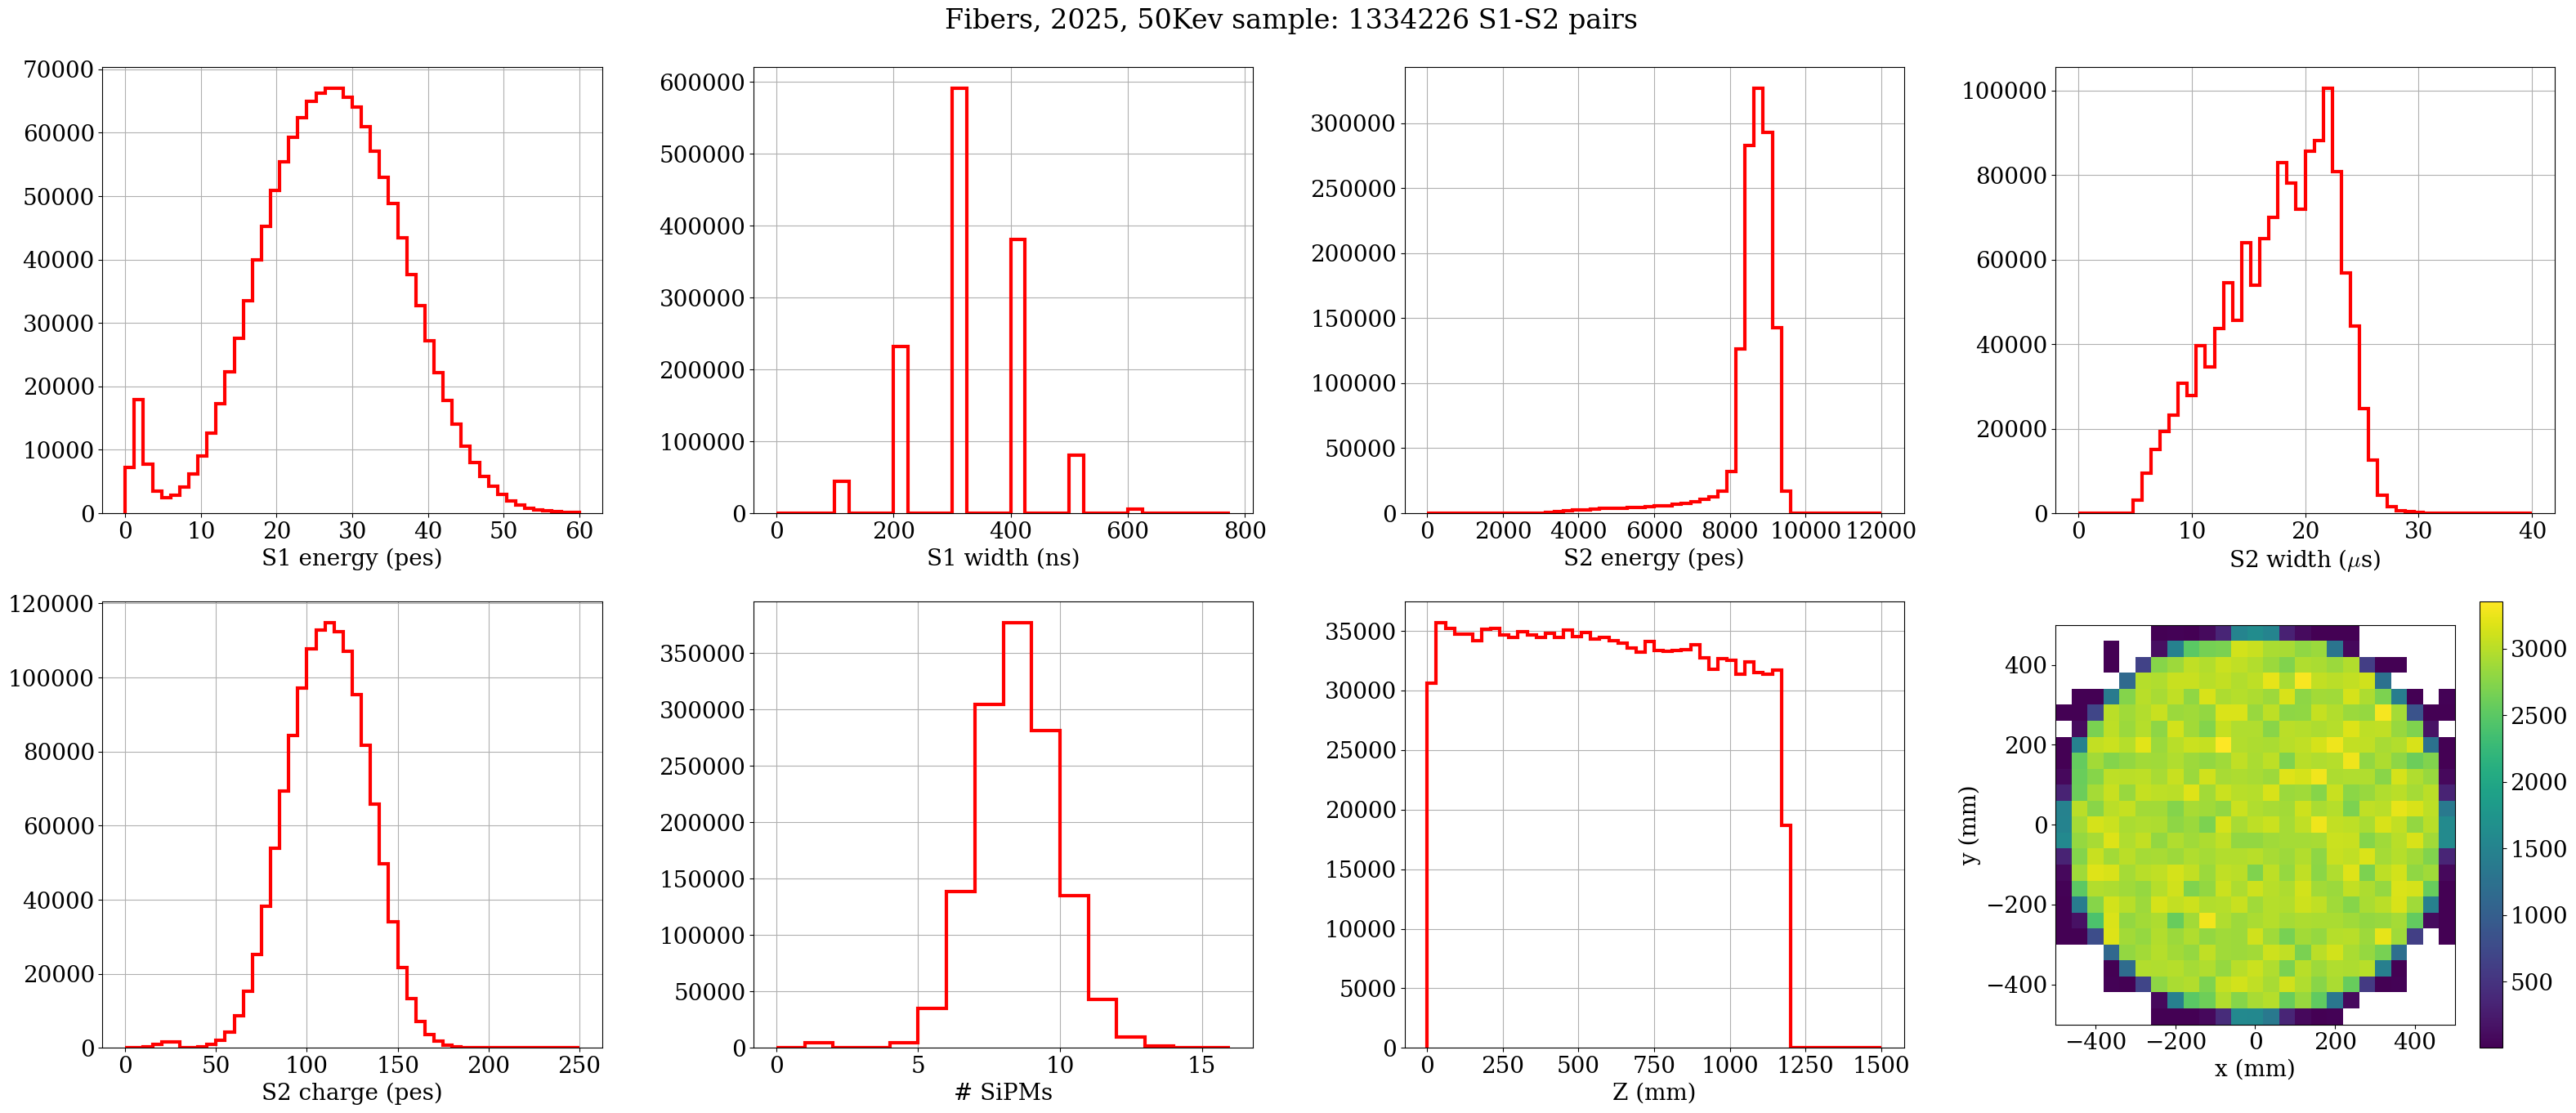

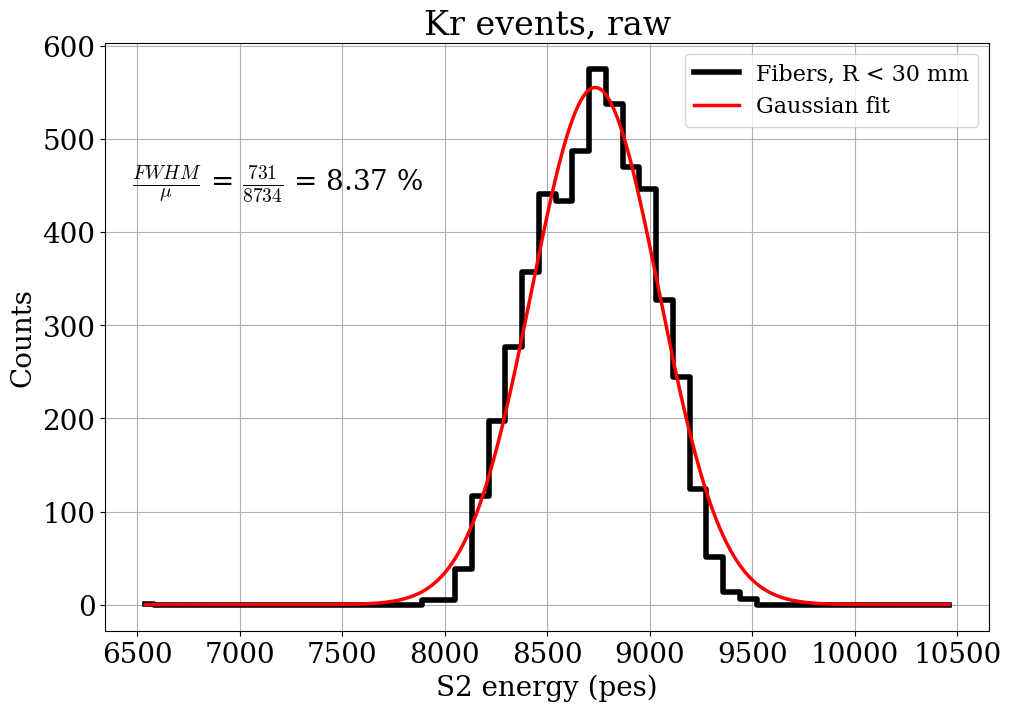

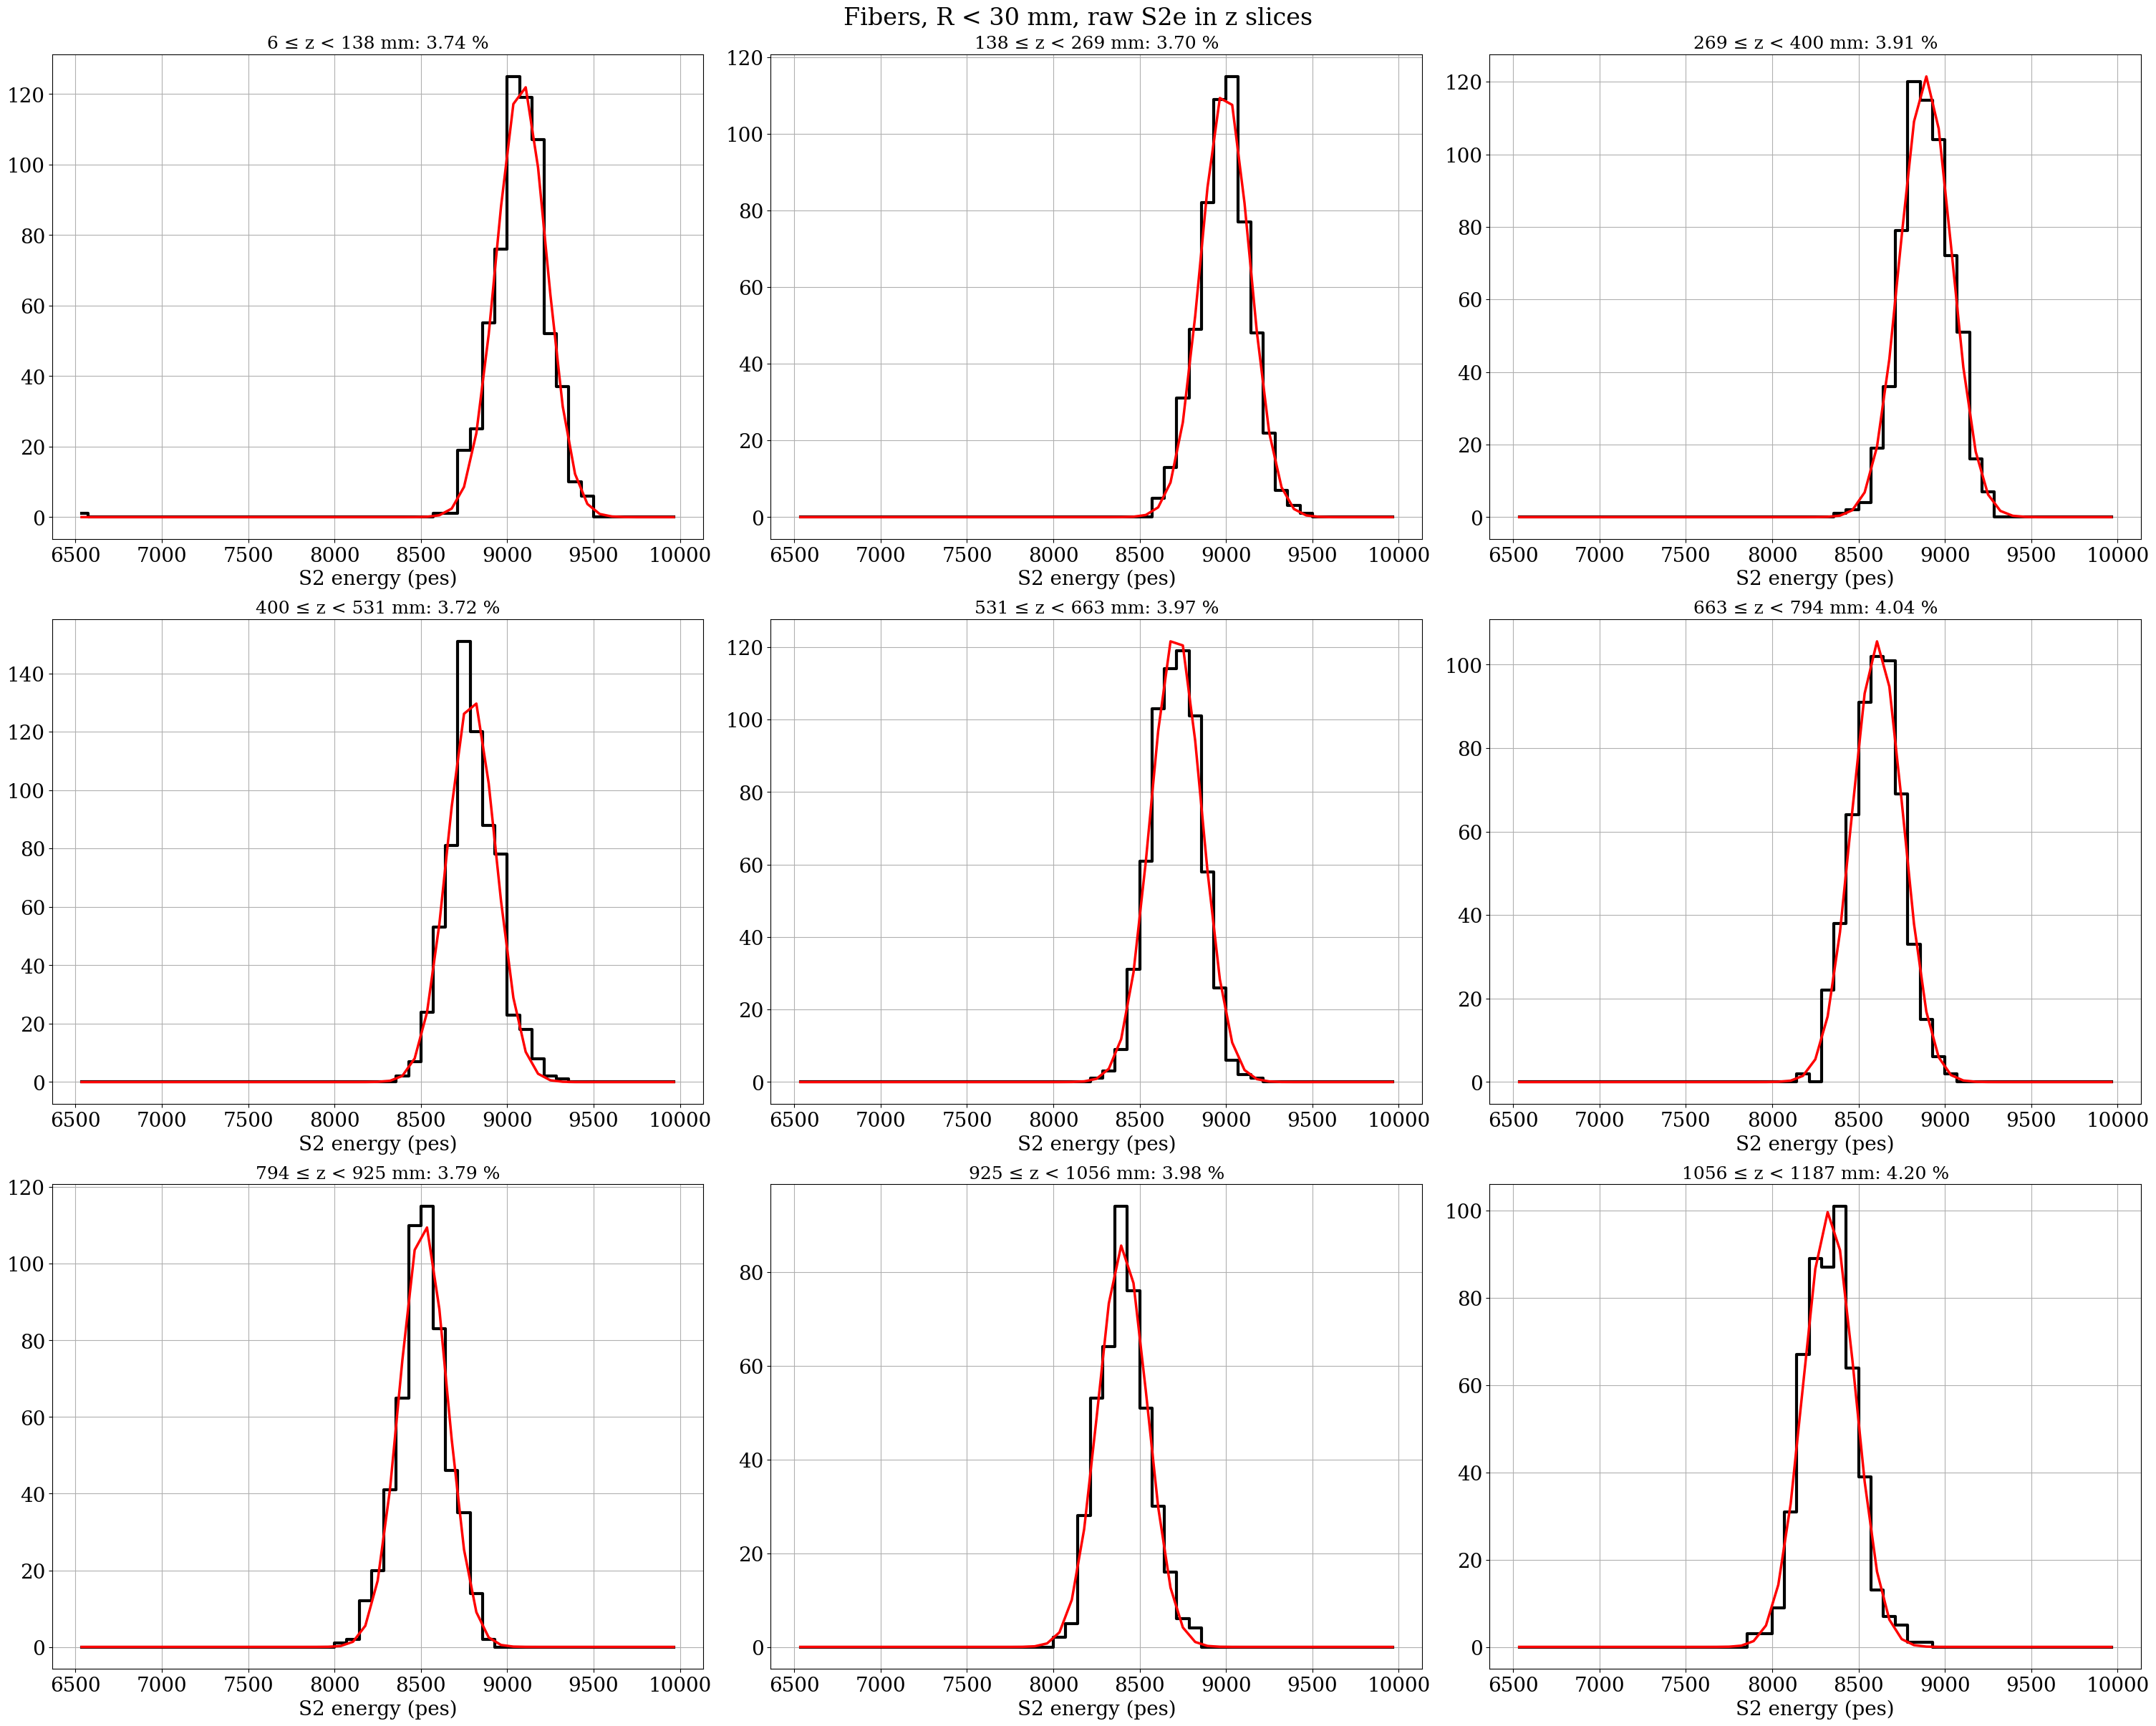

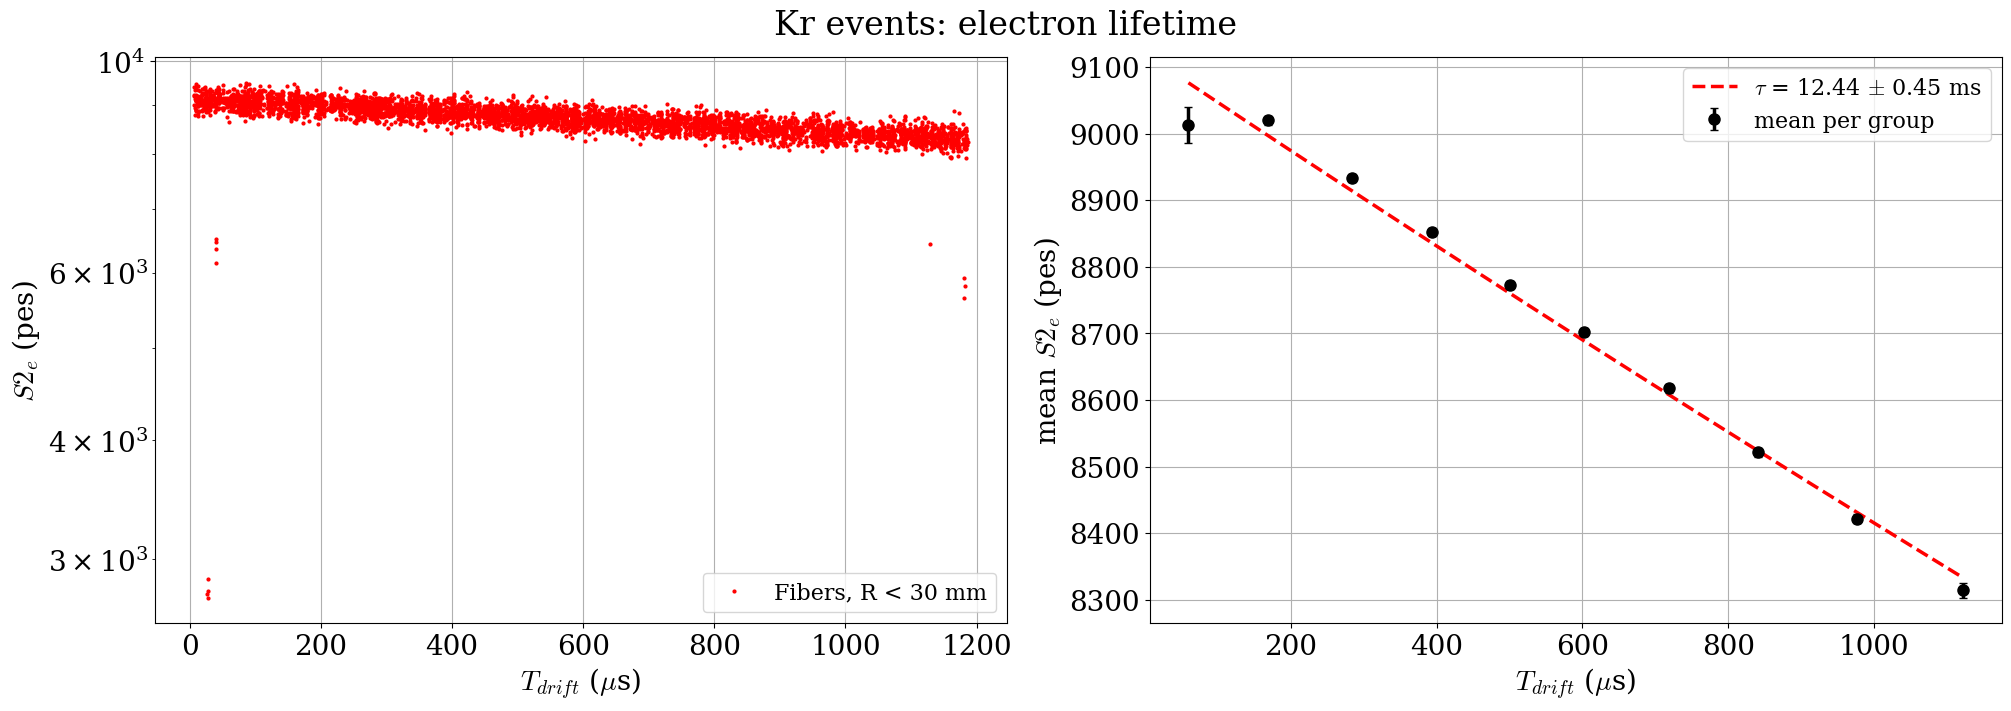

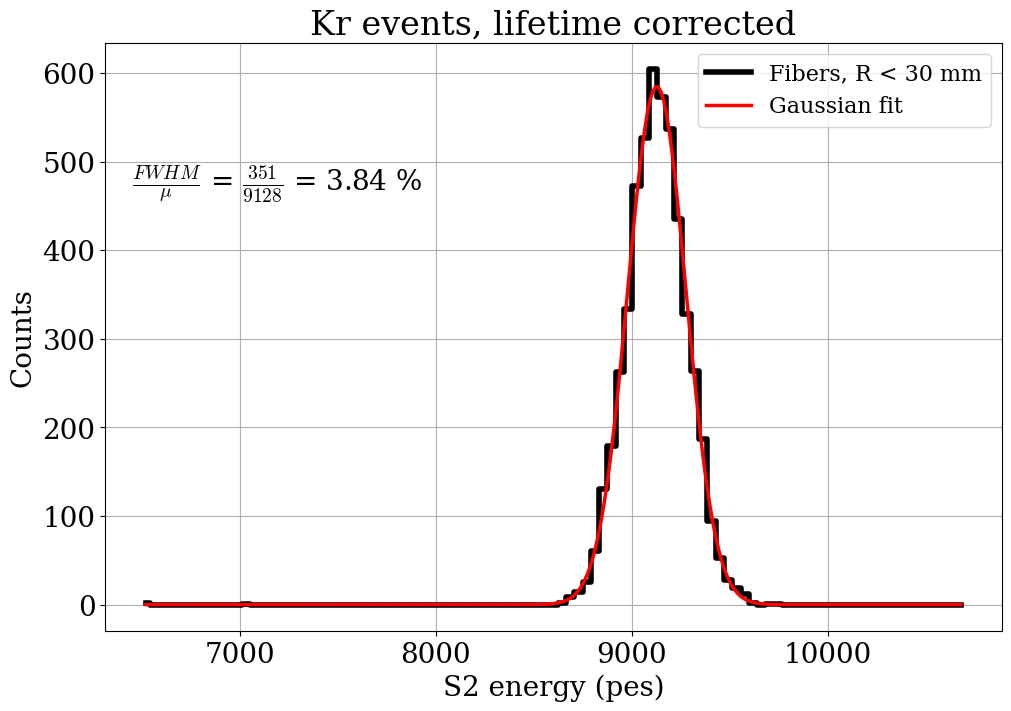

In [4]:
# Plots (2025 style), see the next cell for what each one shows
from icana import plots
plots.set_style()
SAVE = False         # True: also save each figure to work/figures/ (PDF for the thesis, PNG)
def show(fig, name):
    if SAVE: print("saved", plots.save(fig, name))
    plt.show()
d50 = r50["d"]; dt50 = d50.Z.values / V_DRIFT
show(plots.dst_overview(dst50, "Fibers, 2025, 50Kev sample"), "kr50_fibers_2025_overview")
show(plots.peak_fit(r50["raw"], f"Fibers, R < {RCUT} mm", "Kr events, raw"), "kr50_fibers_2025_peak_raw")
show(plots.peak_in_z_slices(dst50, RCUT, np.linspace(6.5e3, 1.0e4, 50)), "kr50_fibers_2025_peak_zslices")
show(plots.lifetime(dt50, d50.S2e.values, r50["lt"], f"Fibers, R < {RCUT} mm"), "kr50_fibers_2025_lifetime")
show(plots.peak_fit(r50["cor"], f"Fibers, R < {RCUT} mm", "Kr events, lifetime corrected"), "kr50_fibers_2025_peak_corrected")

**What the plots show** (same as `python_cluster/notebooks/20250614_s2simulation_ICdorothea.ipynb`):
1. **Overview** of the kDST (one row per S1-S2 pair): S1 and S2 energy and width, S2 charge on the SiPMs, number of SiPMs, Z, and the x-y map. All events, before cuts.
2. **Raw Kr peak**: S2 energy for R < 30 mm with a Gaussian fit, no correction. Broad, because electrons are lost while drifting.
3. **The same in 9 z slices**: each slice is narrower, and the peak moves down with z: that is the lifetime.
4. **Lifetime**: S2e vs drift time (left); the means in 10 equal-count groups and the exponential fit (right), τ to compare with the 12 ms put into detsim.
5. **Corrected Kr peak**: S2e × exp(t/τ). This FWHM is the result (2025: 3.84 %).

`SAVE = True` writes them to `work/figures/` (names start with `kr50_fibers_2025_`).

## Fibers vs PMTs on the same nexus events (1Kev sample)
Same cuts and fits. Expected from photostatistics + Fano (Claude's estimate with el_gain 365, not a result): about 3.3% fibers, 3.9% PMTs.

With R < 30 mm the 1Kev sample has only ~150 events per detector, too few for a precise comparison. The full comparison, on the 50Kev sample at gain 1050, is in the next section.

In [5]:
res = {}
for det in ["fibers", "pmts"]:
    dst, fs = load_dst("20250624_Next100_1Kev_ELoff_Kr", det); print(fs)
    res[det] = kr_resolution(dst, f"{det}, 1Kev", **BINS_2025)
print(f"S2 ratio fibers/PMTs (corrected peak): {res['fibers']['cor']['mu']/res['pmts']['cor']['mu']:.3f}")

['/scratch/marian/ic-course/data/20250624_Next100_1Kev_ELoff_Kr_ALL.dorothea.h5']
fibers, 1Kev [2025 method]: 151 events with R < 30 mm
   raw       : mu 8790 pes, FWHM 6.79 ± 0.38 %
   lifetime  : 12.56 ± 0.42 ms (input 12 ms)
   corrected : mu 9132 pes, FWHM 3.44 ± 0.12 %
['/scratch/marian/ic-course/data/20250624_Next100_1Kev_ELoff_Kr_ALL_PMTs.dorothea.h5']
pmts, 1Kev [2025 method]: 157 events with R < 30 mm
   raw       : mu 5608 pes, FWHM 7.03 ± inf %
   lifetime  : 12.68 ± 1.06 ms (input 12 ms)
   corrected : mu 5834 pes, FWHM 4.66 ± inf %
S2 ratio fibers/PMTs (corrected peak): 1.565


### Fibers vs PMTs, plots (2025 style)
The same overview with both detectors on top of each other (PMTs black, fibers red), and the ratio of the mean S1 and S2 energies. The last panel is S1 vs S2 per event.
Then the corrected Kr peak of each detector. Uses `res` from the cell above (1Kev sample; with the new runs, the 50Kev sample).

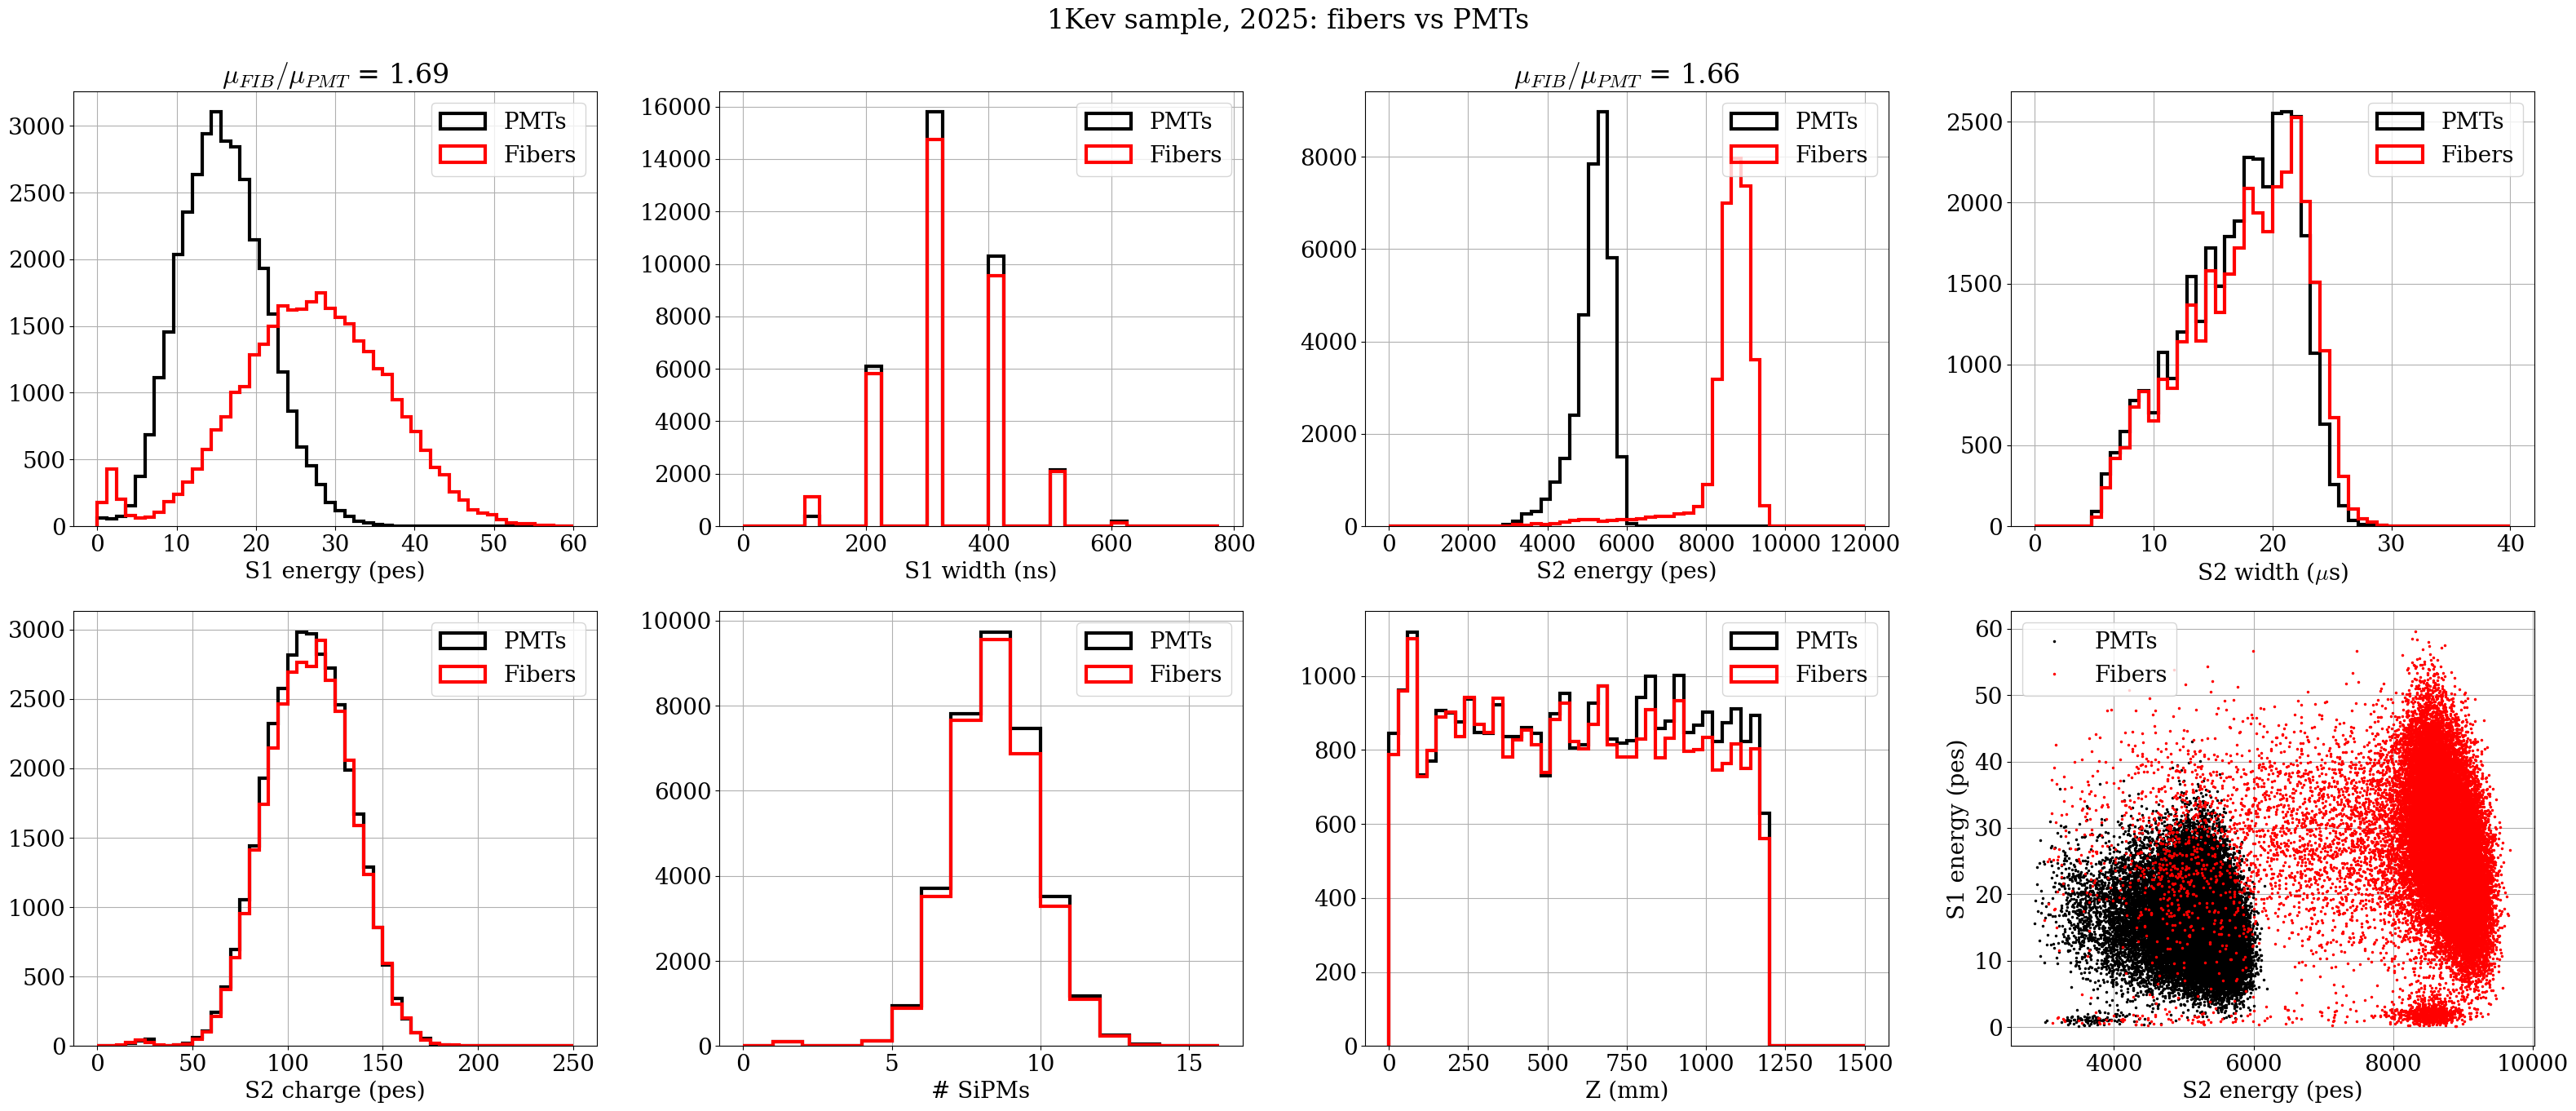

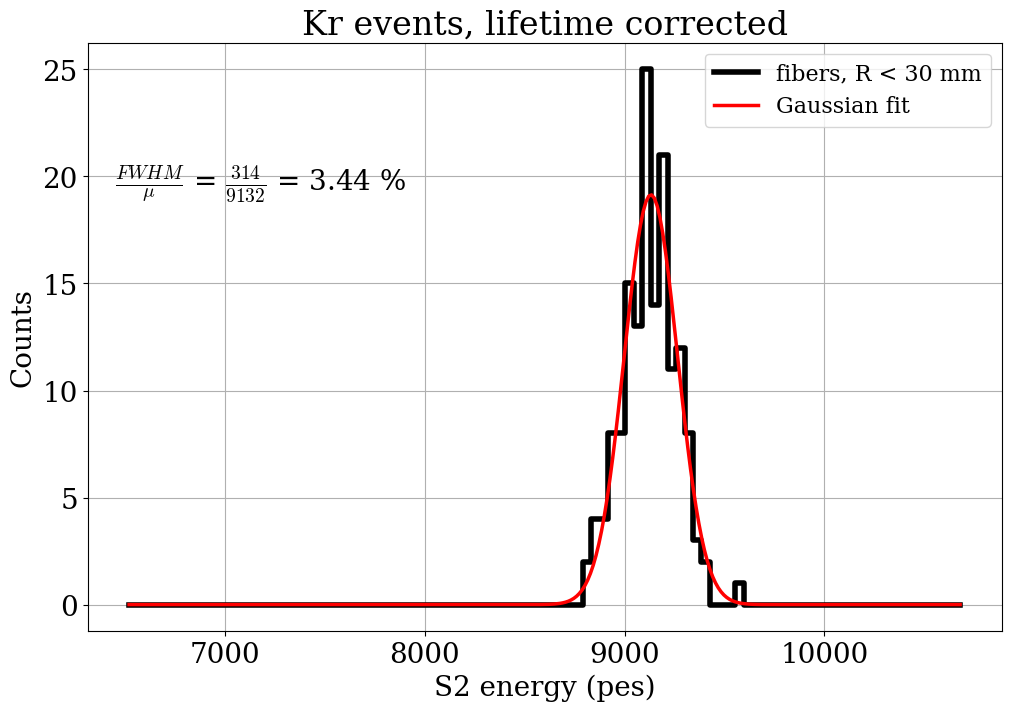

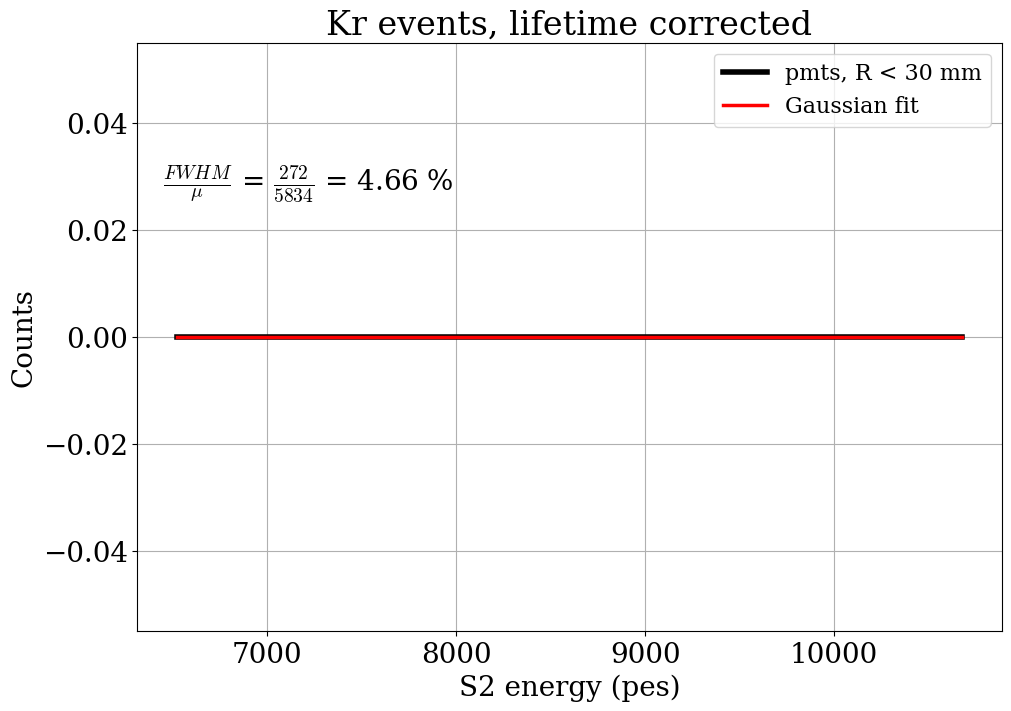

In [6]:
dfib, _ = load_dst("20250624_Next100_1Kev_ELoff_Kr", "fibers"); dpmt, _ = load_dst("20250624_Next100_1Kev_ELoff_Kr", "pmts")
show(plots.dst_compare(dfib, dpmt, "1Kev sample, 2025: fibers vs PMTs"), "kr1_2025_fib_vs_pmt")
for det in ["fibers", "pmts"]:
    show(plots.peak_fit(res[det]["cor"], f"{det}, R < {RCUT} mm", "Kr events, lifetime corrected"), f"kr1_{det}_2025_peak_corrected")

## Gain 1050, 50Kev sample: fibers vs PMTs
The new runs (EL gain 1050, diffusion 1.072 / 0.267 mm/√cm, lifetime 12 ms), 200 chunk files per detector, the same 2 million nexus events for both. Same cuts and fits as above; the fit ranges are placed around each peak (see `REL_RAW`, `REL_COR`).

First numbers (2026-11-22, same code as a script): fibers 3.07 % FWHM (5203 events, τ = 12.23 ms), PMTs 3.46 % (5423 events, τ = 12.84 ms), fibers/PMTs corrected S2 = 1.56. The ± on the FWHM is the fit error only.

Not only the gain changed with respect to 2025: the diffusion did too, so 3.84 % → 3.07 % for fibers is not a pure gain effect.

In [ ]:
SAMPLE50 = "20250626_Next100_50Kev_ELoff_Kr"
new = {}
for det in ["fibers", "pmts"]:
    dst, fs = load_dst(SAMPLE50, det, use_new=True)
    print(f"{det}: {len(fs)} files in {os.path.dirname(fs[0])}")
    new[det]       = kr_resolution(dst, f"{det}, 50Kev, gain {EL_GAIN}")
    new[det + "w"] = kr_resolution(dst, f"{det}, 50Kev, gain {EL_GAIN}", weighted=True)
    new[det]["dst"] = dst
print(f"S2 ratio fibers/PMTs (corrected peak): {new['fibers']['cor']['mu'] / new['pmts']['cor']['mu']:.3f}")
print(f"Gain check, fibers: corrected peak {new['fibers']['cor']['mu'] / r50['cor']['mu']:.3f} x the 2025 one (1050/365 = {1050/365:.3f})")

pd.DataFrame({
    "2025 fibers (g365)": [r50["d"].shape[0], r50["raw"]["fwhm_pct"], r50["lt"]["tau_us"] / 1e3, r50["cor"]["mu"], r50["cor"]["fwhm_pct"], r50w["cor"]["fwhm_pct"]],
    f"fibers (g{EL_GAIN})": [new["fibers"]["d"].shape[0], new["fibers"]["raw"]["fwhm_pct"], new["fibers"]["lt"]["tau_us"] / 1e3, new["fibers"]["cor"]["mu"], new["fibers"]["cor"]["fwhm_pct"], new["fibersw"]["cor"]["fwhm_pct"]],
    f"PMTs (g{EL_GAIN})":   [new["pmts"]["d"].shape[0],   new["pmts"]["raw"]["fwhm_pct"],   new["pmts"]["lt"]["tau_us"] / 1e3,   new["pmts"]["cor"]["mu"],   new["pmts"]["cor"]["fwhm_pct"],   new["pmtsw"]["cor"]["fwhm_pct"]],
}, index=["events R < 30 mm", "raw FWHM (%)", "lifetime (ms)", "corrected peak (pes)", "corrected FWHM (%)", "corrected FWHM, weighted (%)"]).round(2)

### Gain 1050, plots
Overview of both kDSTs on top of each other (S2 axes stretched by 1050/365), then for each detector the lifetime fit and the corrected Kr peak. Names start with `kr50_g1050_`.

In [ ]:
GS = EL_GAIN / 365
show(plots.dst_compare(new["fibers"]["dst"], new["pmts"]["dst"], f"50Kev sample, gain {EL_GAIN}: fibers vs PMTs", gain_scale=GS), f"kr50_g{EL_GAIN}_fib_vs_pmt")
for det in ["fibers", "pmts"]:
    r = new[det]; d = r["d"]
    show(plots.lifetime(d.Z.values / V_DRIFT, d.S2e.values, r["lt"], f"{det}, R < {RCUT} mm"), f"kr50_g{EL_GAIN}_{det}_lifetime")
    show(plots.peak_fit(r["cor"], f"{det}, R < {RCUT} mm", "Kr events, lifetime corrected"), f"kr50_g{EL_GAIN}_{det}_peak_corrected")